# Fast Reflexes on the Robot and a Slow World-Model Brain on Anyscale

### Serve a robot's **world model** in the cloud with Ray, and reconcile its *always-late* advice with the robot's real-time reflex

Today's robot policies (VLAs) are brilliant **reflexes**. They transform observations into actions in one shot. However, a reflex
can't *deliberate*. A **world model** is a learned model of *what happens next given an action*. It lets a
robot **imagine and search** for a good action. That search is heavy (billion-parameter rollouts over many
imagined futures), so it belongs in the cloud. LLMs crossed this same line with **test-time compute**
(the "think longer, answer better" behind o1-style reasoning). This is its control analogue.

But the moment you put the thinking in the cloud, you inherit a hard, unsolved problem. That being **the cloud's
answer is always stale.** It is computed for where the robot *was* when it asked, and it arrives seconds
later, after the fast reflex has already moved on. Naively applying stale advice is *worse* than ignoring it as it adds a correction meant for the old pose onto the new one, sending the robot to a spot neither it nor the cloud intended.

> The unlock is **reconciliation**, where you may choose to fuse the live reflex with the delayed cloud correction so the robot
> ends up where the cloud's smarter plan intended, *starting from where it actually is now*.

Note that **reconciliation is an open research problem.** If we define the original snapshot pose as `p0` (where the robot was when it asked), and the cloud's advised move as `a_cloud`. The vector-addition rule we use here, where we treat the cloud's answer as an intended destination (i.e. `p0` + `a_cloud`) and steer toward it, is the simplest instance, and the one we demonstrate. But *how* you should fuse a stale plan with a live reflex is deeply context-dependent, and the logic can be complex. In a fast, dynamic setting the robot may need to **ignore** the cloud's target and trust its fast policy instead. Say, if something dangerous has appeared right where the cloud pointed (falling debris, a person stepping in, an object that moved since the snapshot, etc). Richer reconcilers might blend the two by staleness, hand control to the reflex when a correction is too old or unsafe, or *learn* the fusion per embodiment. We show the clean vector-add case to make the idea concrete and treat it as the first example.

**And this is a Ray + Anyscale workload end to end**. The slow brain is a **Ray Serve** service, and
scaling it (more GPUs → faster plans → *less staleness to reconcile*) is a config change, not a rewrite.

| What serving this needs | Assemble it yourself | On Ray + Anyscale |
|---|---|---|
| Serve a multi-GB GPU model over HTTP | FastAPI + a process manager, load the model per worker, wire up health checks and GPU pinning | `@serve.deployment(num_gpus=1)` — model loaded once per replica, HTTP ingress included *(shown here)* |
| Make one plan faster (shard the search across GPUs) | Custom multiprocessing / NCCL, your own RPC and result-gather | `ShardWorker` actors + fan-out/reduce — near-linear, **18.4 s → 4.3 s on 4 L4s** *(shown here)* |
| Serve a fleet of robots | A Deployment + external load balancer + readiness probes | `.options(num_replicas=N)` — the Serve proxy load-balances |
| Scale to demand | Cluster-autoscaler + HPA + custom GPU metrics, tuned by hand | Replica **and** node autoscaling, built in |
| Get 11 GB of weights + your code onto every GPU | Bake into images and rebuild on every change and run a registry | Shared cluster storage + `runtime_env` ships code and deps — no image rebuild |
| Go from laptop → dev cluster → prod | Different stacks locally vs. in prod + dealing with config drift | The *same* `serve.run` everywhere — the dev cluster mirrors prod |

*The first two rows run live in this notebook. The rest are the production path the same code grows into.*

## This is Mission Control's problem, generalized

A spacecraft (the fast brain) flies itself second-by-second. It never freezes waiting for Earth. Mission
Control (the slow cloud) works out a maneuver from telemetry that's already minutes old, so the command
arrives *stale* as it was computed for where the craft *was*, not where it is. That's exactly why the ground may choose to send
a **destination**. This is the target state to reach rather than raw stick-and-throttle commands. The craft
closes the gap to that intended state from wherever it actually is at present time.

Autonomous-driving stacks already run this split with heavy compute off-vehicle and a tightly-budgeted policy
on the car. We generalize it with a **learned world model** the robot can search inside, so it works for
general-purpose robots where you can't hand-author a simulator. Our substrate is Meta's open,
action-conditioned **V-JEPA 2-AC** (MIT). Planning is done via the **Cross-Entropy Method** (sample actions, roll
them forward *in latent space*, keep the ones whose imagined outcome lands closest to the goal).

**One idea to hold onto** is that V-JEPA doesn't predict pixels. Rather, it compresses each observation into a compact
*latent* and predicts how that latent changes when the robot acts. All the searching happens in that
latent space. The robot's 7-D end-effector **pose** is what we reconcile in.

## The architecture

![architecture](images/architecture.png)

The fast reflex acts on the robot in milliseconds and steers toward a destination. The slow world-model
brain is **served on Anyscale with Ray Serve** and thinks in seconds. The **reconciler** fuses the cloud's
always-late corrected destination into the robot's live motion. Everything below builds and runs exactly
this loop, end-to-end, on the cluster.

## 1. Connect to the cluster

We ship our modules to every node with `py_modules` and point the world-model weight cache at shared
cluster storage so each GPU loads the 11 GB checkpoint locally.

In [1]:
import os, sys, time, pickle, warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("ray.serve").setLevel(logging.ERROR)  # keep the notebook output to the narrative
import numpy as np
import requests
import matplotlib.pyplot as plt
import ray
from ray import serve
from IPython.display import Image

REPO = "/home/ray/default/robotics_world_model_inference/v2_reconciliation"
TORCH_HOME = "/mnt/cluster_storage/torch_hub"
VJEPA_REPO = f"{TORCH_HOME}/hub/facebookresearch_vjepa2_main"
sys.path.insert(0, REPO)

# log_to_driver=False keeps the notebook clean: the slow brain's per-CEM-step and Ray Serve logs stay on
# the worker nodes; we only surface the robot client's own progress lines here.
ray.init(address="auto", logging_level="ERROR", log_to_driver=False, runtime_env={
    "py_modules": [f"{REPO}/vjepa_core.py", f"{REPO}/slow_brain_service.py",
                   f"{REPO}/world.py", f"{REPO}/robot_client.py"],
    "env_vars": {"TORCH_HOME": TORCH_HOME, "HF_HOME": "/mnt/cluster_storage/hf_cache",
                 "PYTORCH_CUDA_ALLOC_CONF": "expandable_segments:True"},
})
print("cluster GPUs available:", int(ray.cluster_resources().get("GPU", 0)))

cluster GPUs available: 4


## 2. Serve the slow brain on Ray Serve

This is the Anyscale core: the world model is a **`@serve.deployment`** — loaded once per GPU replica,
fronted by HTTP. A robot POSTs a snapshot (its latent + pose + the goal latent); the service runs CEM in
latent space and returns an action toward the goal. Scaling out is `.options(num_replicas=N)`.

In [2]:
from slow_brain_service import build_app

serve.run(build_app(samples=32, cem_steps=4, rollout=2), name="slow_brain", route_prefix="/")
URL = "http://127.0.0.1:8000"
print("slow brain health:", requests.get(URL + "/health", timeout=120).json())

INFO 2026-07-01 14:54:56,267 serve 20550 -- Started Serve in namespace "serve".
INFO 2026-07-01 14:56:47,583 serve 20550 -- Application 'slow_brain' is ready at http://0.0.0.0:8000/.


slow brain health: {'ok': True, 'calls': 0}


## 3. The task, and the robot's "world"

We use a short Franka manipulation clip shipped with V-JEPA 2: a **context** frame (where the arm is) and
a **goal** frame. The `World` actor is our stand-in for physical reality — it holds the *true* latent +
pose and advances them with the predictor as the robot acts (the robot and cloud only ever see it through
snapshots, like real sensors). We build a goal a few steps away so there's room to move.

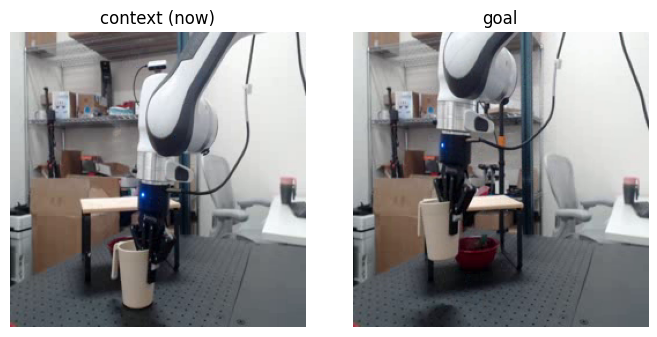

In [3]:
from world import World

world = World.remote()
traj = np.load(f"{VJEPA_REPO}/notebooks/franka_example_traj.npz")
ctx_img, goal_img = traj["observations"][0, 0], traj["observations"][0, 1]
prob = ray.get(world.build_problem.remote(ctx_img, goal_img, traj["states"][0, 0], goal_steps=8))
z_goal = prob["z_goal"]

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
ax[0].imshow(ctx_img); ax[0].set_title("context (now)"); ax[0].axis("off")
ax[1].imshow(goal_img); ax[1].set_title("goal"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. One real cloud plan — and why it can't run on the robot

We POST one real snapshot to the served slow brain and time the round-trip. The world model *thinks* for
seconds; a robot control loop is **10–50 ms**. That gap is the whole problem — the answer is many control
ticks stale by the time it lands.

In [4]:
ray.get(world.reset.remote(prob["z0"], prob["p0"]))
snap = ray.get(world.snapshot.remote())
req = {"z": snap["z"], "pose": snap["pose"], "z_goal": z_goal, "seq_id": 0}

t0 = time.time()
r = requests.post(URL + "/plan", data=pickle.dumps(req),
                  headers={"Content-Type": "application/octet-stream"}, timeout=300)
rtt = (time.time() - t0) * 1000
out = pickle.loads(r.content)
print(f"cloud plan: action chunk {out['chunk'].shape} | server compute {out['compute_ms']:.0f} ms | "
      f"round-trip {rtt:.0f} ms")
print(f"a ~20 ms control loop takes ~{rtt/20:.0f} steps in that time -> the advice is ~{rtt/20:.0f} "
      f"control ticks STALE by the time it arrives")

cloud plan: action chunk (2, 7) | server compute 2741 ms | round-trip 2784 ms
a ~20 ms control loop takes ~139 steps in that time -> the advice is ~139 control ticks STALE by the time it arrives


## 5. Reconciliation: steer to the corrected destination

The cloud's action `a_cloud` was right *for the snapshot pose* `p0`. By the time it lands, the robot has
drifted to `p_now`. Two ways to use it:

- **Naive** — apply `a_cloud` from `p_now`. It was computed from a *different* starting point, so the
  robot carries the drift. Error grows with latency.
- **Vector-add reconciliation** — the cloud implied a **destination** `p0 + a_cloud` ("where I should have
  ended up"). Steer from `p_now` toward that destination: `correction = (p0 + a_cloud) − p_now`. The drift
  cancels. This requires the robot to *retain* `p0` until the matching reply arrives.

That's it — the GPS move, as pure vector arithmetic. Below, the robot runs its fast loop against the
**real** served slow brain: it snapshots, keeps acting while the cloud thinks, and reconciles each reply.
The staleness Δ here is *measured* from the real round-trip.

    [vector_add] tick  9: cloud reply (req@0) Δ=9 ticks, latency=2782ms, pose_err=0.367
    [vector_add] tick 19: cloud reply (req@10) Δ=9 ticks, latency=2777ms, pose_err=0.311

measured staleness Δ ≈ 9 control ticks (from 2780 ms real cloud latency at 3 Hz)


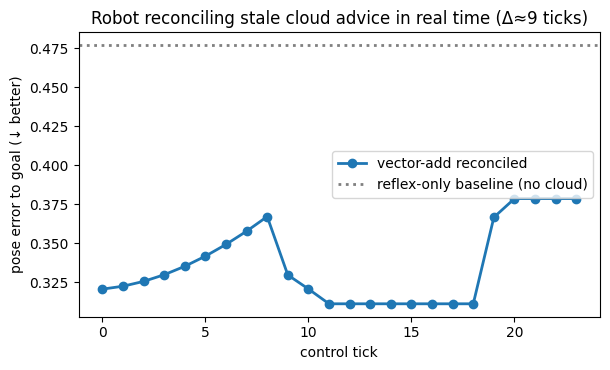

In [5]:
from robot_client import run_episode

DRIFT = [0.0, 0.02, 0.0, 0.0, 0.0, 0.0, 0.0]   # a small unmodeled disturbance (miscalibration/push)
ray.get(world.reset.remote(prob["z0"], prob["p0"]))
res = run_episode(world, URL, z_goal, strategy="vector_add", control_hz=3.0,
                  horizon=24, drift=DRIFT, samples=32, cem_steps=4, rollout=2)

print(f"\nmeasured staleness Δ ≈ {res['mean_delta']:.0f} control ticks "
      f"(from {res['mean_latency_ms']:.0f} ms real cloud latency at 3 Hz)")
plt.figure(figsize=(6.2, 3.8))
plt.plot(res["pose_err"], "o-", color="C0", lw=2, label="vector-add reconciled")
plt.axhline(0.477, color="gray", ls=":", lw=2, label="reflex-only baseline (no cloud)")
plt.xlabel("control tick"); plt.ylabel("pose error to goal (↓ better)")
plt.title(f"Robot reconciling stale cloud advice in real time (Δ≈{res['mean_delta']:.0f} ticks)")
plt.legend(); plt.tight_layout(); plt.show()

## 6. The payoff: reconciliation vs. naive, as the cloud goes stale

A single run is noisy (only a few corrections). The chart below is the controlled, seed-averaged sweep
(measured offline on this cluster; reproducible via `p1_run.py`). We use **pose error to the goal** — an
exact metric — as the primary signal, with the world model's own latent **energy** as corroboration.

As cloud latency Δ grows, **naive** degrades toward the reflex-only baseline, while **vector-add
reconciled** stays low. That's the thesis: reconciliation is what lets you use a late-but-smart cloud
without it hurting you.

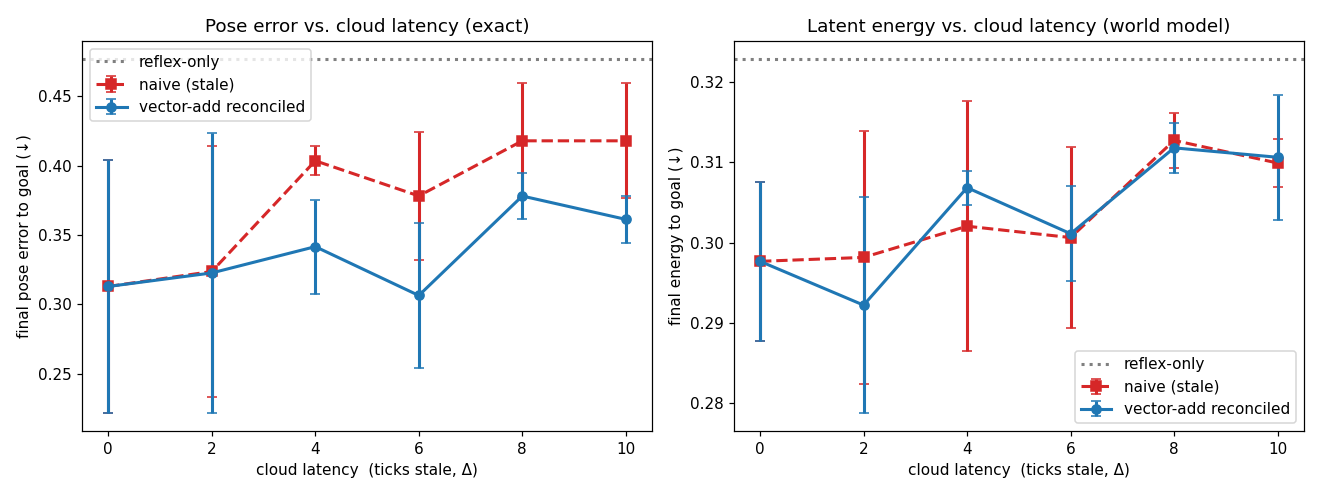

In [6]:
Image(filename=f"{REPO}/images/p1_feasibility.png")

## 7. Scale the slow brain on Anyscale — faster plans, smaller Δ

The staleness Δ is set by how fast the cloud can answer. **Ray lets us shard one CEM plan's sample batch
across GPUs** — each GPU rolls part of the search, a coordinator takes the global best and refits. More
GPUs → a faster plan → **less staleness to reconcile.** Measured on our 4× L4s below (reproducible via
`p2_shard_test.py`): near-linear, an **18.4 s plan → 4.3 s** across 4 GPUs.

This is the whole scaling story in one knob. On production accelerators (H100/H200/B200) the *same* code
drops it toward sub-second — the curves just shift down and to the left; the fast brain still runs in ms
on the robot regardless.

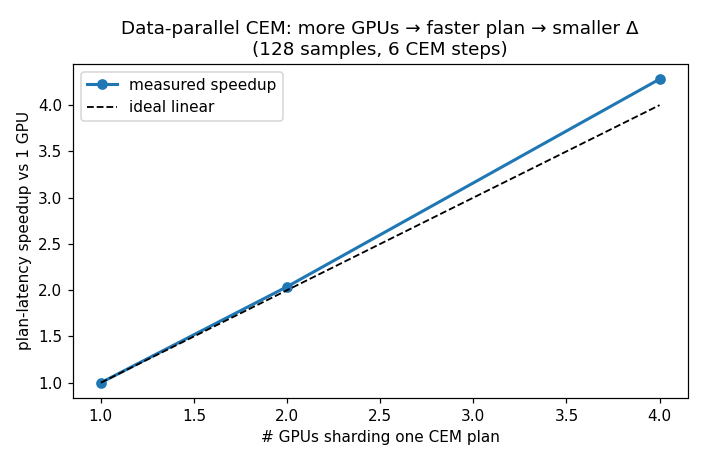

In [7]:
Image(filename=f"{REPO}/images/p2_shard_scaling.png")

## 8. Δ is a dial — the production consideration

Staleness isn't a fixed number; it's the ratio of cloud latency to the robot's control period, and it's a
**design dial**:

- **Slow the robot** (deliberate tasks — careful insertion, easing through a doorway) → Δ shrinks to a few
  ticks. But you can't slow a *balancing* or *fast-contact* task without it falling over — those need
  100–1000 Hz, which pushes Δ into the hundreds.
- **Speed up the cloud** (more GPUs via the shard lever above, faster accelerators, fp8 / `torch.compile`
  / FlashAttention) → Δ shrinks with no change to the robot.

The one thing you *can't* do is make Δ zero: the cloud is always slower than the reflex (that's why it's a
separate brain), so some staleness always remains — and reconciliation is what makes running the two
brains at different speeds safe. Crank the robot faster and Δ grows, so reconciliation matters *more*, not
less. **Planning is elastic cloud compute; the reflex is a cheap edge policy; reconciliation is the glue.**

## 9. The standing architecture

Run this continuously: the fast reflex acts on the robot in milliseconds; the **slow brain thinks in the
cloud on Anyscale**, served with Ray and scaled by a number; and a reconciliation layer fuses the cloud's
always-late, always-smarter corrections into the robot's live motion. Fast brain on the robot, slow brain
on Anyscale — with the hard part, *reconciling the two*, done honestly.

In [8]:
ray.kill(world)
serve.shutdown()
print("slow brain + world released.")

(raylet) Task ServeController.graceful_shutdown failed. There are infinite retries remaining, so the task will be retried. Error: The actor is dead because it was killed by `ray.kill`.
slow brain + world released.
